# CENG313 Assignment 1 — EDA and Baselines

**Group 11:** Ahmet Can Gümüş (23118080007) · Muhammed Taha Eren (23118080020)
**Competition:** [RSNA Intracranial Aneurysm Detection](https://www.kaggle.com/competitions/rsna-intracranial-aneurysm-detection) (Kaggle)

This notebook summarises our exploratory data analysis and the baseline models. The detailed analyses are in
[`notebooks/01_eda_labels.ipynb`](notebooks/01_eda_labels.ipynb), [`notebooks/02_eda_dicom_meta.ipynb`](notebooks/02_eda_dicom_meta.ipynb), [`notebooks/04_eda_images.ipynb`](notebooks/04_eda_images.ipynb) and [`notebooks/03_baselines.ipynb`](notebooks/03_baselines.ipynb); the code is in `src/`.

**Summary**
- 4,348 brain scans (CTA, MRA, MRI T2, MRI T1post), 42.8% with an aneurysm. The 13 locations are rare (1–8% each).
- The positive rate depends strongly on the modality (CTA 54%, MRI 25%), the sex and the age. The scans differ a lot in
  size and resolution (15 to 1,441 slices, 0.25 to 10 mm between slices).
- Every scan is cached as a 160 × 192 × 192 volume of 1 mm voxels, cut from the top of the head.
- With the same 5-fold CV and the competition metric: B0 (mean) 0.500, B1 (age, sex, modality) 0.666, B2 (CNN on MIPs) 0.679,
  and B1 + B2 together 0.708. The image model is clearly better than B1 inside CTA and MRA, but not on MRI.
- Kaggle late submission: B1-DICOM, a version of B1 that reads its inputs from the DICOM header. CV 0.694,
  Kaggle public 0.610 and private 0.585 (section 6).

### Who did what

| Part | Who |
| --- | --- |
| Choice of competition, project plan | Both |
| Repo setup, environment | Ahmet Can |
| Competition metric, CV split, shared evaluation code (`src/utils.py`) | Muhammed Taha |
| EDA: labels, demographics, localizers, DICOM metadata of all series, images (`01`, `02`, `04`, `kaggle/extract_dicom_meta.py`) | Muhammed Taha |
| Preprocessing and cached volumes of all series (`src/data.py`, Kaggle scripts) | Ahmet Can |
| Baselines B0 and B1 ([`notebooks/03_baselines.ipynb`](notebooks/03_baselines.ipynb)) | Muhammed Taha |
| Baseline B2 (`src/train_b2.py`, `src/models.py`) and the B1 + B2 idea | Ahmet Can |
| B1-DICOM and the Kaggle submission (`kaggle/submit_b1_notebook.py`) | Ahmet Can |
| This write-up and the README | Both |

Both of us read and checked each other's code. The progress log in `README.md` lists every step with its date.

## 1. Task and metric

Each sample is one *series*: a 3D scan made of many 2D slices. For every series the model predicts 14 probabilities:
*Aneurysm Present* and 13 artery locations. The metric is the weighted mean of the 14 AUCs, with weight 13 for
*Aneurysm Present* and 1 for each location, so half of the score is the *Aneurysm Present* AUC
(`src.utils.competition_score`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data import VOLUME_SHAPE, load_volume, make_mips, volume_paths
from src.utils import ID_COL, LOCATION_COLS, TARGET_COL, cv_report, load_folds, rank_average

train = pd.read_csv(ROOT / "data" / "raw" / "train.csv")
meta = pd.read_csv(ROOT / "data" / "interim" / "dicom_meta.csv")   # kaggle/extract_dicom_meta.py
SAMPLE = ROOT / "data" / "volumes_sample"                            # a few volumes of group11-volumes
loc_vox = pd.read_csv(SAMPLE / "localizers_vox.csv")
df = train.merge(meta.drop(columns=["Modality", "PatientAge", "PatientSex"]), on=ID_COL)

MODALITIES = ["CTA", "MRA", "MRI T2", "MRI T1post"]
BLUE, ORANGE, AQUA, YELLOW, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#52514e"
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True,
    "axes.edgecolor": GRAY, "axes.labelcolor": GRAY, "xtick.color": GRAY, "ytick.color": GRAY,
})

## 2. Data overview

In [2]:
overview = pd.DataFrame({
    "series": train.groupby("Modality").size(),
    "positive": train.groupby("Modality")[TARGET_COL].sum(),
    "positive rate": (train.groupby("Modality")[TARGET_COL].mean() * 100).round(1),
    "median slices": df.groupby("Modality")["n_slices"].median(),
    "median slice spacing (mm)": df.groupby("Modality")["slice_spacing"].median().round(2),
}).loc[MODALITIES]
overview.loc["all"] = [len(train), train[TARGET_COL].sum(), round(train[TARGET_COL].mean() * 100, 1),
                       df["n_slices"].median(), round(df["slice_spacing"].median(), 2)]
print("Full data: 311 GB, about 1.0M DICOM files.")
overview

Full data: 311 GB, about 1.0M DICOM files.


,series,positive,positive rate,median slices,median slice spacing (mm)
Modality,,,,,
CTA,1808,973,53.8,334.0,0.62
MRA,1252,555,44.3,164.0,0.55
MRI T2,983,258,26.2,30.0,5.00
MRI T1post,305,77,25.2,166.0,1.00
all,4348,1863,42.8,176.0,0.70


In [ ]:
loc = pd.read_csv(ROOT / "data" / "raw" / "train_localizers.csv")
for name, table in [("train.csv", train), ("train_localizers.csv", loc)]:
    print(f"{name}: {table.shape[0]:,} rows x {table.shape[1]} columns | missing values: {table.isna().sum().sum()} | "
          f"duplicate rows: {table.duplicated().sum()} | different series: {table[ID_COL].nunique():,}")
print("\ntrain.csv column types:", ", ".join(f"{c} ({t})" for c, t in train.dtypes.astype(str).items()
                                             if c not in LOCATION_COLS), f"and the 13 locations ({train[LOCATION_COLS[0]].dtype})")

summary = train.drop(columns=ID_COL).describe(include="all").T
for col in ["mean", "std"]:
    summary[col] = pd.to_numeric(summary[col]).round(3)
summary[["count", "unique", "top", "freq", "mean", "std", "min", "max"]]

- `train.csv` has one row per series: age, sex, modality and the 14 labels. No missing values, no duplicate rows or series.
  Age is an integer from 18 to 89 (median 60), sex and modality are text, the labels are 0/1.
  The mean of each label is its positive rate: 42.8% for *Aneurysm Present*, 1.1% to 8.3% for the locations.
- `train_localizers.csv` marks 2,254 aneurysms with a point on one slice. **3 rows are exact copies** of another row
  (one point written twice in one series and three times in another). They don't affect the baselines, which don't use
  the points, but they have to be dropped before the points are used as a training target in Assignment 2.
- The images are DICOM files. Most series have one file per slice; 322 series are one multi-frame file.

In [ ]:
header = meta.drop(columns=[ID_COL, "error"], errors="ignore")
missing = (header.isna().mean() * 100).round(1)
print(f"dicom_meta.csv: {meta.shape[0]:,} rows x {meta.shape[1]} columns | duplicate series: {meta[ID_COL].duplicated().sum()}")
print("PatientSex in the header:", meta["PatientSex"].value_counts(dropna=False).to_dict())
print("\nMissing values in the DICOM headers (% of series):")
print(missing[missing > 0].sort_values(ascending=False).to_string())

The tables from Kaggle are clean, but the DICOM headers are not. Age is missing in 27% of the headers and sex in 15%
(another 8% say "O"); tags that only exist on MR, such as `MagneticFieldStrength`, are missing on CT series, which are 42% of the data.
B1 uses `train.csv` and needs no imputation. The Kaggle submission (section 6) has no `train.csv` for the test series
and must read the headers, so its model has to deal with these gaps (section 4.2).

## 3. Exploratory data analysis

### 3.1 Labels

Aneurysm Present = 1 exactly when at least one location is 1: True


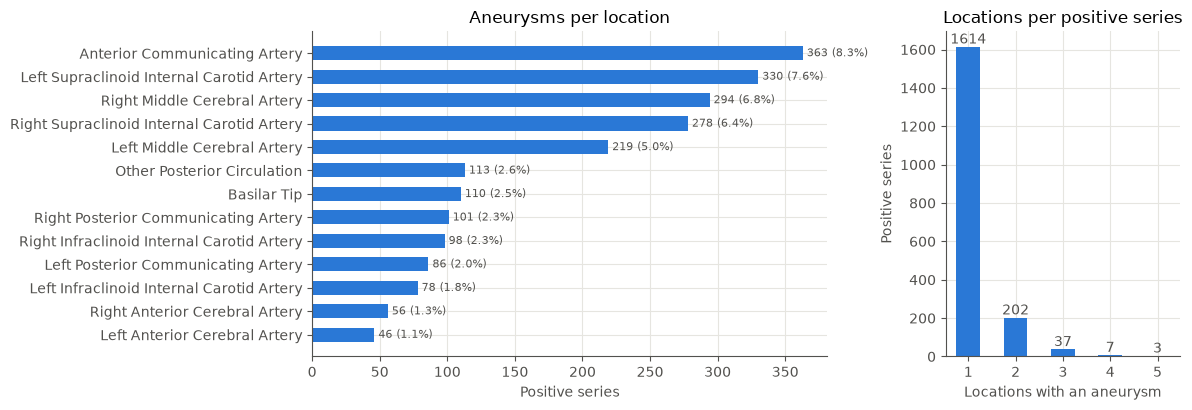

In [3]:
loc_counts = train[LOCATION_COLS].sum().sort_values()
n_locations = train.loc[train[TARGET_COL] == 1, LOCATION_COLS].sum(axis=1).value_counts().sort_index()
consistent = ((train[LOCATION_COLS].sum(axis=1) > 0).astype(int) == train[TARGET_COL]).all()
print("Aneurysm Present = 1 exactly when at least one location is 1:", consistent)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
ax1.barh(loc_counts.index, loc_counts.values, color=BLUE, height=0.6)
for i, v in enumerate(loc_counts.values):
    ax1.text(v + 3, i, f"{v} ({v / len(train):.1%})", va="center", color=GRAY, fontsize=8)
ax1.set_xlabel("Positive series"); ax1.set_title("Aneurysms per location")
ax2.bar(n_locations.index.astype(str), n_locations.values, color=BLUE, width=0.5)
for i, v in enumerate(n_locations.values):
    ax2.text(i, v, str(v), ha="center", va="bottom", color=GRAY)
ax2.set_xlabel("Locations with an aneurysm"); ax2.set_ylabel("Positive series")
ax2.set_title("Locations per positive series")
plt.tight_layout(); plt.show()

*Aneurysm Present* is fairly balanced (42.8%), but each location is rare: from 363 series (Anterior Communicating Artery)
down to 46 (Left Anterior Cerebral Artery). 249 positive series (13%) have aneurysms in more than one location,
so the location task is multi-label. The labels are consistent with each other and with the localizer points.

### 3.2 Modality, sex and age

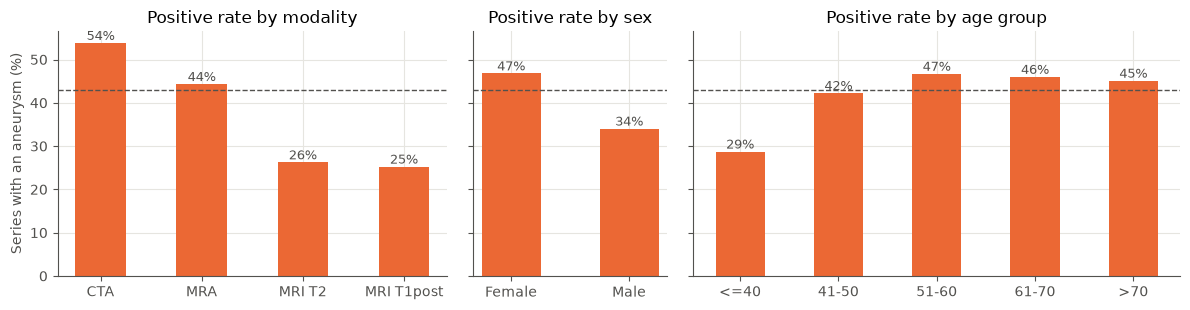

Series per sex: {'Female': 3005, 'Male': 1343} | age: {'min': 18.0, '50%': 60.0, 'max': 89.0}


In [4]:
age_group = pd.cut(train["PatientAge"], [0, 40, 50, 60, 70, 100], labels=["<=40", "41-50", "51-60", "61-70", ">70"])
rates = [
    ("Modality", train.groupby("Modality")[TARGET_COL].mean().loc[MODALITIES]),
    ("Sex", train.groupby("PatientSex")[TARGET_COL].mean()),
    ("Age group", train.groupby(age_group, observed=True)[TARGET_COL].mean()),
]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True, gridspec_kw={"width_ratios": [4, 2, 5]})
for ax, (title, rate) in zip(axes, rates):
    ax.bar(rate.index.astype(str), rate.values * 100, color=ORANGE, width=0.5)
    for i, v in enumerate(rate.values * 100):
        ax.text(i, v, f"{v:.0f}%", ha="center", va="bottom", color=GRAY, fontsize=9)
    ax.axhline(train[TARGET_COL].mean() * 100, color=GRAY, ls="--", lw=1)
    ax.set_title(f"Positive rate by {title.lower()}")
axes[0].set_ylabel("Series with an aneurysm (%)")
plt.tight_layout(); plt.show()
print("Series per sex:", train["PatientSex"].value_counts().to_dict(), "| age:", train["PatientAge"].describe()[["min", "50%", "max"]].to_dict())

The positive rate is 54% for CTA but about 25% for MRI, 47% for women and 34% for men (69% of the series are women),
and much lower under 40. This reflects how the data was collected (which patients get which scan), not only biology.
It means that a model can score above 0.5 without looking at the image at all, which is what baseline B1 measures.

### 3.3 DICOM metadata

We read the headers of all 4,348 series on Kaggle without loading the pixels (`kaggle/extract_dicom_meta.py`, 51 minutes).

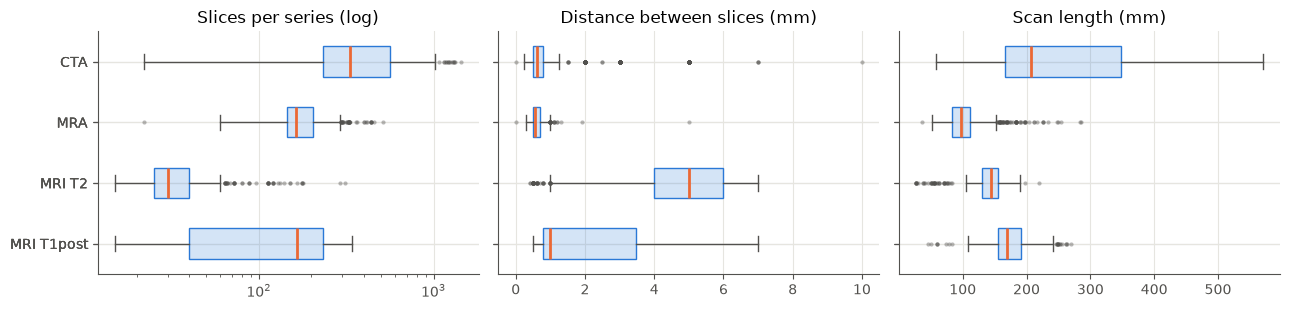

Unique PatientID: 4348 of 4348 series
Multi-frame series: 322 | image sizes: 164
CTA longer than 250 mm: 808


In [5]:
def box_by_modality(ax, col, title, log=False):
    data = [df.loc[df["Modality"] == m, col].dropna() for m in MODALITIES]
    ax.boxplot(data, orientation="horizontal", tick_labels=MODALITIES, widths=0.5, patch_artist=True,
               boxprops=dict(facecolor="#2a78d633", edgecolor=BLUE), medianprops=dict(color=ORANGE, lw=2),
               whiskerprops=dict(color=GRAY), capprops=dict(color=GRAY),
               flierprops=dict(marker="o", ms=3, mfc=GRAY, mec="none", alpha=0.4))
    if not ax.yaxis_inverted():
        ax.invert_yaxis()
    if log:
        ax.set_xscale("log")
    ax.set_title(title)


fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
box_by_modality(axes[0], "n_slices", "Slices per series (log)", log=True)
box_by_modality(axes[1], "slice_spacing", "Distance between slices (mm)")
box_by_modality(axes[2], "z_extent_mm", "Scan length (mm)")
plt.tight_layout(); plt.show()

print("Unique PatientID:", df["PatientID"].nunique(), "of", len(df), "series")
print("Multi-frame series:", df["is_multiframe"].sum(), "| image sizes:", (df["Rows"].astype(str) + "x" + df["Columns"].astype(str)).nunique())
print("CTA longer than 250 mm:", ((df["Modality"] == "CTA") & (df["z_extent_mm"] > 250)).sum())

- **No patient overlap:** every series has its own `PatientID`, so the CV split does not need patient grouping.
- **Very different scans:** CTA has a median of 334 thin slices, MRI T2 only 30 slices of 5 mm. Image sizes vary (164 sizes).
  Volumes must be resampled by physical size (mm), not by slice count.
- **Scan length:** 808 CTAs are longer than 250 mm (up to 570 mm) and include the neck and chest, while MRA covers only about 100 mm.
  The head has to be cropped before resizing.
- **Header traps:** `SliceThickness` differs from the real distance between slices in a third to half of the series,
  and many CT headers say `RescaleIntercept = -1024` although the pixels are already in HU.

### 3.4 Images

One positive series per modality from the cached volumes (section 4): an axial slice through the localizer point (circle),
and the maximum intensity projection (MIP) from the top that baseline B2 uses.

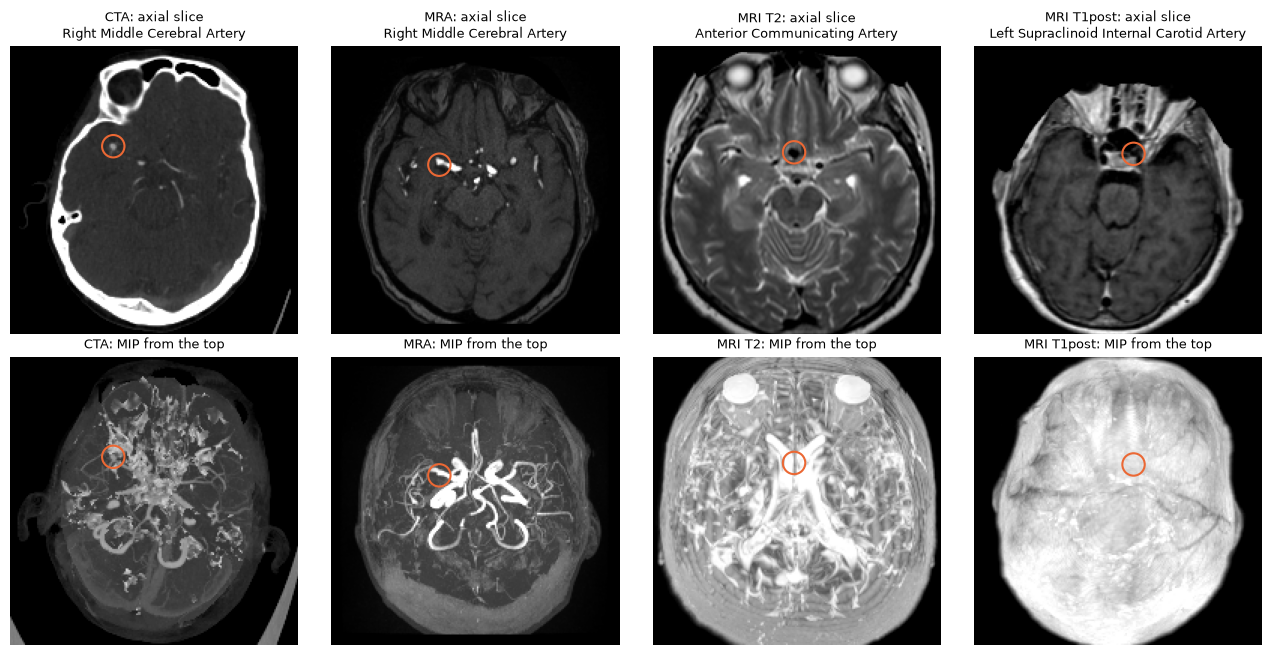

In [6]:
paths = volume_paths(SAMPLE / "volumes")
modality_of = train.set_index(ID_COL)["Modality"]
one_point = loc_vox.groupby(ID_COL).filter(lambda g: len(g) == 1).set_index(ID_COL)
BONE_FREE_CTA = "1.2.826.0.1.3680043.8.498.10760644681012726742070280772751417129"
examples = {modality_of[u]: u for u in paths if u in one_point.index and u != BONE_FREE_CTA}

fig, axes = plt.subplots(2, 4, figsize=(13, 6.6))
for col, modality in enumerate(MODALITIES):
    uid = examples[modality]
    v = load_volume(paths[uid])
    p = one_point.loc[uid]
    z, y, x = int(round(p["z"])), p["y"], p["x"]
    mip = make_mips(v, is_ct=modality == "CTA")[0][0]
    for ax, img, title in [(axes[0, col], v[z], f"{modality}: axial slice\n{p['location']}"),
                           (axes[1, col], mip, f"{modality}: MIP from the top")]:
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        ax.scatter([x], [y], s=260, facecolors="none", edgecolors=ORANGE, linewidths=1.5)
        ax.set_title(title, fontsize=9)
        ax.axis("off")
plt.tight_layout(); plt.show()

On CTA and MRA the arteries are bright, and the MIP shows the vessel tree with the aneurysm on it (on CT the skull is removed first).
On MRI T2 the bright structure is fluid, and on MRI T1post fat and scalp; their MIPs do not show the vessels.
36 CTAs are bone-subtracted (no skull); 31 of them are positive, a possible shortcut for a model ([`notebooks/04_eda_images.ipynb`](notebooks/04_eda_images.ipynb)).

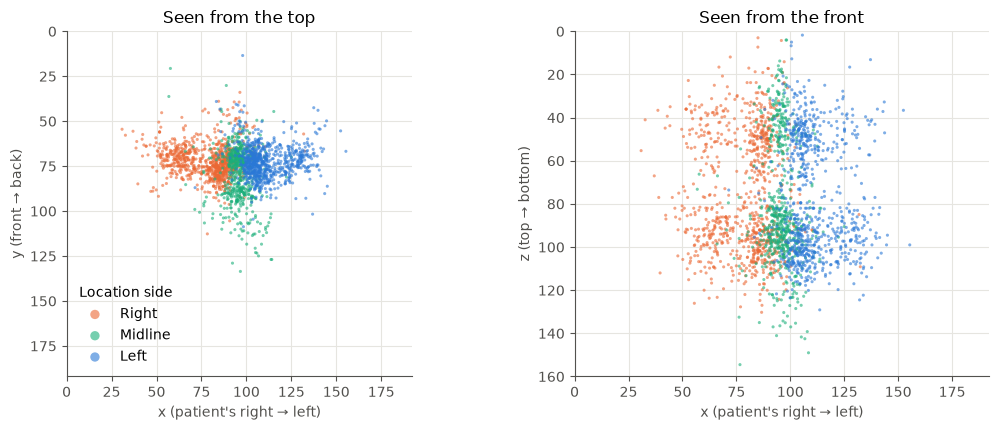

All 2254 localizer points, median depth z: MRA 47 mm, other modalities 94 mm


In [7]:
side = np.where(loc_vox["location"].str.startswith("Left"), "Left",
                np.where(loc_vox["location"].str.startswith("Right"), "Right", "Midline"))
is_mra = loc_vox[ID_COL].map(modality_of).eq("MRA")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))
for name, color in [("Right", ORANGE), ("Midline", AQUA), ("Left", BLUE)]:
    pts = loc_vox[side == name]
    ax1.scatter(pts["x"], pts["y"], s=5, color=color, alpha=0.6, label=name, edgecolors="none")
    ax2.scatter(pts["x"], pts["z"], s=5, color=color, alpha=0.6, label=name, edgecolors="none")
for ax, ylabel, ymax, title in [(ax1, "y (front → back)", VOLUME_SHAPE[1], "Seen from the top"),
                                (ax2, "z (top → bottom)", VOLUME_SHAPE[0], "Seen from the front")]:
    ax.set_xlim(0, VOLUME_SHAPE[2]); ax.set_ylim(ymax, 0); ax.set_aspect("equal")
    ax.set_xlabel("x (patient's right → left)"); ax.set_ylabel(ylabel); ax.set_title(title)
ax1.legend(title="Location side", frameon=False, markerscale=3)
plt.tight_layout(); plt.show()
print(f"All {len(loc_vox)} localizer points, median depth z: MRA {loc_vox.loc[is_mra, 'z'].median():.0f} mm, "
      f"other modalities {loc_vox.loc[~is_mra, 'z'].median():.0f} mm")

All aneurysms are in a small region in the middle of the head (the circle of Willis). Left, right and midline labels
match the x position, which confirms the orientation of the cached volumes. MRA scans start lower than the top of the head,
so their aneurysms sit higher in the box.

## 4. Preprocessing

### 4.1 Images (cached volumes for B2)

`src/data.py` turns every series into one uint8 volume (`ahmetcan0/group11-volumes` on Kaggle, about 8 GB, 4 hours, no errors):
1. Read all slices (one file per slice or multi-frame) and sort them by position; drop duplicate positions.
2. Turn every volume to the same axes (top → bottom, front → back, right → left); 154 coronal or sagittal scans become axial.
3. Cut a 160 × 192 × 192 mm box from the top of the head (removes the neck and chest of long CTAs) and resample it to 1 mm voxels.
4. Scale intensities to 0–255: CT with a fixed window of −100 to 700 HU, MR with the 0.5–99.9 percentiles of the head.
   The CT rescale is applied only when no raw value is negative, which skipped it for all CTs (pixels already in HU).
5. Convert the localizer points to volume coordinates; all 2,254 points are inside the box.

**Why:** the scans differ in orientation, length, resolution and intensity scale (section 3.3). A model needs the same
anatomy at the same place and size in every input, so every scan is reoriented, cropped by physical size (mm, not
slices) and resampled. CT values are in HU, so one fixed window fits all CTs; MR has no absolute scale, so each MR
is scaled by its own percentiles. 1 mm voxels keep small aneurysms (a few mm) visible while the 4,348 volumes
still fit in 8 GB.

### 4.2 Tabular inputs (B1 and B1-DICOM)

- **Missing values.** `train.csv` has none, so B1 needs no imputation. B1-DICOM (section 6) reads the DICOM header,
  where age (27% missing), sex (23% missing or "O") and the MR tags on CT series are missing. We keep them as NaN
  instead of filling in a value: LightGBM learns at each split on which side missing values go, and a missing value
  carries information itself (an empty echo time means CT). Filling in the median would make every unknown patient
  60 years old and hide that.
- **Encoding.** Sex and modality are one-hot encoded for logistic regression (B1-LR) and given to LightGBM as a
  category (B1-LGBM). In B1-DICOM, text tags become numbers: age `"045Y"` → 45, sex M/F → 1/0, acquisition 3D/2D → 1/0,
  contrast agent present → 1.
- **Free text.** The series description is written by each hospital. We only keep four keyword flags (angio/TOF, T1, T2,
  post-contrast) that tell the MR types apart, because the `Modality` tag only says CT or MR. The raw text is not used:
  some descriptions name the clinical question (one CTA is called "Aneurysm"), which says nothing about the image.
- **Scaling.** Not needed for trees. In B1-LR, age goes through a spline (5 knots) instead of a linear term, because its
  effect is not a straight line: the positive rate rises until about 50 and then stays flat (section 3.2).

## 5. Baseline models

### 5.1 Evaluation

Every model uses the same setup, so the scores are comparable:
- **5-fold CV** (`splits/folds.csv`), stratified by modality and by the rarest aneurysm location of each series.
  Each fold has about 870 series, 42.8% positives, the same modality mix, and at least 8 positives of every location.
- Each model is trained on 4 folds and predicts the 5th (`src.utils.run_cv`), which gives one out-of-fold (OOF) prediction per series.
- Each fold is scored with the competition metric on its own, and the 5 scores are averaged (`src.utils.cv_report`).
- OOF predictions are saved in `results/oof_<model>.csv`.

### 5.2 Models

| ID | Model | Input | Code |
| --- | --- | --- | --- |
| B0 | Training-set mean of every label | nothing | [`notebooks/03_baselines.ipynb`](notebooks/03_baselines.ipynb) |
| B1-LR | Logistic regression per label (spline for age) | age, sex, modality | [`notebooks/03_baselines.ipynb`](notebooks/03_baselines.ipynb) |
| B1-LGBM | LightGBM per label (small trees) | age, sex, modality | [`notebooks/03_baselines.ipynb`](notebooks/03_baselines.ipynb) |
| B2 | ResNet18 (ImageNet) on 3-view MIPs, 14 outputs; bone removed on CT; left-right flip with swapped labels | images | `src/train_b2.py` (Kaggle GPU) |
| B1 + B2 | Mean of the ranks of B1-LGBM and B2 in each fold, equal weights, no tuning | both | `src.utils.rank_average` |
| B1-DICOM | LightGBM per label, B1-LGBM settings | age, sex and scan type tags, all from the DICOM header | `src.models.fit_b1_dicom` (Kaggle CPU) |

- **B0** is a sanity check: equal predictions give an AUC of exactly 0.5; a higher score would mean labels leak into the predictions.
- **B1** shows how much can be predicted from the patient and the scanner only.
- **B2** is the first image model. Its training loss keeps falling while the validation score is flat after about 9 epochs (overfitting).
- **B1-DICOM** is B1 with inputs that also exist for the hidden test series; it is our Kaggle submission (section 6).

In [8]:
oofs = {name: pd.read_csv(ROOT / "results" / f"oof_{file}.csv")
        for name, file in [("B0", "b0"), ("B1-LR", "b1_lr"), ("B1-LGBM", "b1_lgbm"), ("B2", "b2"), ("B1-DICOM", "b1_dicom")]}
oofs["B1 + B2"] = rank_average([oofs["B1-LGBM"], oofs["B2"]])
folds = load_folds()
assert all(o.set_index(ID_COL)["fold"].reindex(folds[ID_COL]).tolist() == folds["fold"].tolist() for o in oofs.values())

reports = {name: cv_report(train, oof) for name, oof in oofs.items()}
table = pd.DataFrame({
    name: {
        "CV score": f"{r['summary']['cv_score']:.3f} ± {r['summary']['cv_std']:.3f}",
        "Aneurysm Present AUC": round(r["summary"]["present_auc"], 3),
        "Mean location AUC": round(r["summary"]["mean_location_auc"], 3),
        **{m: round(r["per_modality"][m], 3) for m in MODALITIES},
    }
    for name, r in reports.items()
}).T
table

,CV score,Aneurysm Present AUC,Mean location AUC,CTA,MRA,MRI T2,MRI T1post
B0,0.500 ± 0.000,0.5,0.5,0.5,0.5,0.5,0.5
B1-LR,0.659 ± 0.007,0.675,0.644,0.583,0.602,0.596,0.595
B1-LGBM,0.666 ± 0.010,0.676,0.655,0.59,0.619,0.668,0.65
B2,0.679 ± 0.012,0.704,0.654,0.668,0.647,0.57,0.624
B1 + B2,0.708 ± 0.005,0.727,0.69,0.676,0.678,0.652,0.667


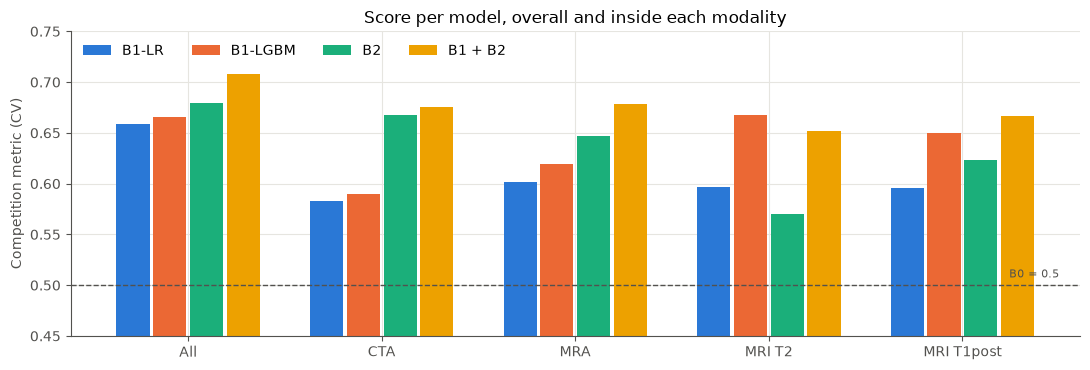

In [9]:
models = ["B1-LR", "B1-LGBM", "B1-DICOM", "B2", "B1 + B2"]
colors = [BLUE, ORANGE, GRAY, AQUA, YELLOW]
groups = ["All"] + MODALITIES
values = {m: [reports[m]["summary"]["cv_score"]] + [reports[m]["per_modality"][g] for g in MODALITIES] for m in models}

fig, ax = plt.subplots(figsize=(11, 3.8))
width = 0.16
for i, (model, color) in enumerate(zip(models, colors)):
    pos = np.arange(len(groups)) + (i - 2) * width
    ax.bar(pos, values[model], width * 0.9, color=color, label=model)
ax.axhline(0.5, color=GRAY, ls="--", lw=1)
ax.text(len(groups) - 0.5, 0.505, "B0 = 0.5", ha="right", va="bottom", color=GRAY, fontsize=8)
ax.set_xticks(range(len(groups)), groups)
ax.set_ylim(0.45, 0.75)
ax.set_ylabel("Competition metric (CV)")
ax.set_title("Score per model, overall and inside each modality")
ax.legend(frameon=False, ncol=5, loc="upper left")
plt.tight_layout(); plt.show()

### 5.3 Results

- **B0 = 0.500** on every fold: the evaluation code does not leak labels.
- **B1 ≈ 0.66** (LR 0.659, LightGBM 0.666) without any image. Modality, sex and age carry real signal.
- **B2 = 0.679** is only slightly above B1 overall, but the per-modality columns tell more. Inside one modality,
  B1 loses its main advantage (the link between modality and positive rate):
  - on **CTA** B2 is far better (0.668 vs 0.590) and on **MRA** better (0.647 vs 0.619), so it learns from the vessels;
  - on **MRI T2** (0.570) and **MRI T1post** (0.624) it is worse than B1, because their MIPs do not show the vessels (section 3.4).
- **B1 + B2 = 0.708 ± 0.005**, better than both and the best result so far: the image and the patient data are complementary.
- **B1-DICOM = 0.694 ± 0.008**, above B1 although it has the same kind of input. The gain is inside CTA (0.661 vs 0.590)
  and MRA (0.646 vs 0.619): tags such as slice count, image size and series description tell which hospital and
  protocol a scan comes from, and the positive rate differs between them. This is real signal for the Kaggle test set,
  but it says nothing about the aneurysm itself, so it is a weaker kind of evidence than what B2 learns from the image.

## 6. Kaggle submission

The competition is a **code competition** with late submissions open: Kaggle runs our notebook again on hidden test
series and calls a `predict()` function once per series. A test series has no row in `train.csv`, so B1 cannot be
used as it is, and B2 would need the full preprocessing of every series inside `predict()` (planned for Assignment 2).
B1 + B2 is not possible either, because ranks need all test predictions at once, while `predict()` sees one series at a time.

Our first submission is therefore **B1-DICOM**:
- `src.data.header_features` reads the inputs from the header of the first DICOM file of a series (17 features, section 4.2).
- `src.models.fit_b1_dicom` trains one LightGBM per label on all 4,348 training series.
- `kaggle/submit_b1_notebook.py` is the Kaggle notebook (internet off, CPU): it reads the training headers (43 s),
  prints the CV score, trains, and answers the test series through the competition's inference server. If a test
  series cannot be read, it predicts from missing values instead of failing the submission.

| | Score |
| --- | --- |
| CV (5 folds, our metric code) | 0.694 ± 0.008 |
| Kaggle public score | 0.610 |
| Kaggle private score | 0.585 |

![Kaggle late submission of B1-DICOM](submissions/b1_dicom_late_submission.png)

**Two attempts.** The first version (11 November) failed: the scoring run went over the 12-hour limit, although our
own run takes about 2 minutes. Kaggle does not show the log of the scoring run, so we read the competition's
evaluation code and removed three possible causes in version 2 (12 November): the scoring run takes the training header
features from our code dataset instead of reading all 4,348 series with worker processes, LightGBM predicts with one
thread, and `predict()` removes only the current series from `/kaggle/shared` instead of the whole folder. Version 2
was scored. These are late submissions (the competition has ended), so they are not on the leaderboard.

**CV vs. Kaggle.** The Kaggle scores are clearly lower than the CV score (0.585–0.610 vs 0.694). Our folds are stratified by
modality and location, not split by hospital, so the hospitals and protocols of the validation folds are also in training. If the hidden
test set has a different mix of hospitals and protocols, the header tags that identify them (section 5.3) are worth less
there. This is our most likely explanation, but we can't check it, because the test labels are hidden. For Assignment 2
it means that the CV score of a model that leans on scanner tags is too optimistic, and that the image itself has to
carry the prediction.

## 7. Conclusion

**Key findings**
- *Aneurysm Present* is fairly balanced (42.8%), but the 13 locations are rare and 13% of the positive series have
  more than one. The scans differ a lot (modality, size, resolution, length), so careful preprocessing is needed.
- Without any image, patient and scanner information reaches 0.666 (B1) to 0.694 (B1-DICOM). Most of it comes from the
  link between modality and positive rate, and in B1-DICOM also from tags that identify the hospital and protocol.
- The image model B2 learns from the vessels on CTA and MRA but not on MRI T2 and T1post. Together with B1 it reaches
  0.708, our best CV score.
- Our Kaggle late submission B1-DICOM scores 0.610 public and 0.585 private, well below its CV of 0.694: the header
  tags that identify hospital and protocol seem to transfer less well to the hidden test set (section 6).

**Plan for Assignment 2**
- A 3D CNN on the cached volumes instead of projections, so that MRI can also be used (Option A in `ROADMAP.md`),
  with the localizer points as an extra training target, and age, sex and modality as extra inputs.
- Possibly a second stage on a crop around the circle of Willis at a finer resolution (Option B).
- Watch the overfitting seen in B2 (augmentation, early stopping) and the bone-subtracted CTA shortcut.
- Use the same folds, metric and per-modality table.
- Submit an image model to Kaggle: run the preprocessing of `src/data.py` inside `predict()`.
- Drop the 3 duplicate localizer rows before using the points as a training target.